In [138]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def bounded_degree_bfs_tree(G, root, max_degree=3):
    """
    Constructs a BFS tree with bounded out-degree using dummy nodes.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start BFS.
        max_degree : int
            Maximum number of children a node can have in the tree.

    Returns:
        T : networkx.DiGraph
            Tree with dummy nodes added to enforce degree bounds.
    """
    T = nx.Graph()
    dummy_counter = 0
    visited = set([root])
    queue = deque([root])
    n = G.number_of_nodes()

    while queue:
        parent = queue.popleft()
        children = []

        for neighbor in G.neighbors(parent):
            if neighbor not in visited:
                visited.add(neighbor)
                children.append(neighbor)

        # Split children into groups of size at most `max_degree`
        if len(children) <= max_degree:
            for child in children:
                T.add_edge(parent, child)
                queue.append(child)
        else:
            # First group goes directly under the parent
            for child in children[:max_degree]:
                T.add_edge(parent, child)
                queue.append(child)

            # Remaining go under dummy nodes
            remaining = children[max_degree:]
            first_dummy=True
            while remaining:
                dummy = n + dummy_counter
                dummy_counter += 1
                if first_dummy:
                    T.add_edge(parent, dummy)
                else:
                    T.add_edge(dummy-1, dummy)

                for i in range(min(max_degree, len(remaining))):
                    child = remaining.pop(0)
                    T.add_edge(dummy, child)
                    queue.append(child)             
                first_dummy=False

    return T

def dfs_spanning_tree(G, root):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(edges)
    return G

def find_linear_chain(adj, target_length):
    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

        
def initial_layout(graph : nx.Graph, num_nodes, backend, how='warm', topology='tree', root_on_backend=0):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    fiedler = fiedler[:num_nodes]
    sorted_nodes = np.argsort(fiedler)

    if topology=='chain':
        coupling_map = backend.coupling_map

        # adjacency as a dict: {qubit: [connected_qubits]}
        adj = {i: [] for i in range(backend.configuration().num_qubits)}
        for (i, j) in coupling_map:
            adj[i].append(j)
            adj[j].append(i)

        chain = find_linear_chain(adj, num_nodes)
    else:
        G = get_coupling_graph(backend)

        tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
        dfs_nodes = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

    if how=='warm':
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: dfs_nodes[i] for i in range(num_nodes)}
    elif how=='cold':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def get_hamiltonian(graph):
    def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
        """Convert NetworkX graph to Pauli list for MaxCut."""
        pauli_list = []
        num_nodes = len(graph.nodes())
        
        for edge in graph.edges(data=True):
            u, v, data = edge
            paulis = ["I"] * num_nodes
            
            # NetworkX nodes can be any hashable type, so we use positional indices
            paulis[u] = "Z"
            paulis[v] = "Z"
            
            # Get weight with default 1.0 if not specified
            weight = data.get('weight', 1.0)
            
            # Reverse string to match RustworkX qubit ordering convention
            pauli_list.append(("".join(paulis)[::-1], float(weight)))
        
        return pauli_list
    
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, reps=2, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True, seed=0),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, reps=2, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, mapping=None, opt_level=3):
    if mapping:
        mapping_layout = Layout({q: mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

In [ ]:

def QAOA_max_cut(candidate_circuit:QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, estimator_shots=1000, sampler_shots=1000):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = estimator_shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
    optimized_circuit = candidate_circuit.assign_parameters(result.x)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = sampler_shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin
    # keys = list(final_distribution_bin.keys())
    # values = list(final_distribution_bin.values())
    # most_likely = keys[np.argmax(np.abs(values))]

    # return most_likely[::-1]

def optimized_parameters(candidate_circuit: QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, shots=100):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
        return result.x
    
def sample_distribution(candidate_circuit:QuantumCircuit, optimized_params, backend, shots=1000):
    optimized_circuit = candidate_circuit.assign_parameters(optimized_params)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin

def evaluate_cut(graph: nx.Graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v in list(graph.edges()):
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += 1
    return cut_value

def maxcut_dict(graph, cut_dict):
    mc_dict = defaultdict(int)
    for bitstr, prob in cut_dict.items():
        mc_dict[evaluate_cut(graph, bitstr[::-1])] += prob
    return mc_dict

In [114]:
import networkx as nx
import matplotlib.pyplot as plt
import math

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai', node_size=100, font_size=6, highlight_nodes=None, title=None):
    """
    Draws a NetworkX graph with various options.

    Parameters:
    - G: NetworkX graph
    - node_labels: Whether to show node labels
    - edge_labels: Whether to show edge weights
    - layout: Layout algorithm to use ('spring', 'circular', 'kamada_kawai', etc.)
    - node_size: Size of the nodes
    - font_size: Font size for labels
    """
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        pos = {node: (i % side, -(i // side)) for i, node in enumerate(G.nodes())}
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size, font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [120]:
import networkx as nx
import math

def show_layout_on_backend(circuit, backend, title=None, node_size=150):
    transpiled = circuit

    # Extract assigned physical qubits
    assigned_phys = list(transpiled.layout.final_virtual_layout(filter_ancillas=True).get_physical_bits().keys())

    # Get the coupling map as a NetworkX graph
    coupling_map = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(coupling_map)

    draw_graph_custom(G, highlight_nodes=assigned_phys, title=title, node_size=node_size)

In [288]:
def maxcut_dist(sim, backend, num_nodes, graph_type='reg', param=4, tree_type='dfs', reps=2, opt_level=3, estimator_shots=1000, sampler_shots=1000, root_on_backend=None, want_sabre=True, op_name=None):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    if tree_type=='rand':
        tree = nx.random_spanning_tree(graph, seed=0)
    else:
        tree = dfs_spanning_tree(graph, root=num_nodes//2)

    hamiltonian = get_hamiltonian(graph)
    gen = gen_QAOA_circuit(graph, reps=reps)

    if not root_on_backend:
        root_on_backend = backend.num_qubits//2

    # Distribution with Proposed Initial Mapping
    fied_mapping = initial_layout(tree, num_nodes=num_nodes, backend=backend, how='warm', topology='tree', root_on_backend=root_on_backend)
    prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=reps)
    opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=opt_level)

    # Distribution with no explicit initial mapping set
    opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, mapping=None, opt_level=opt_level)

    if op_name:
        print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
        # print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
        print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())
    
    prop_dist = QAOA_max_cut(opt_prop, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
    gen_dist = QAOA_max_cut(opt_gen, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)

    if want_sabre:
        sabre_mapping = sabre_layout(gen, backend)
        opt_sabre = final_optimized_circuit(gen, backend, sabre_mapping, opt_level=opt_level)
        sabre_dist = QAOA_max_cut(opt_sabre, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)
    else:
        sabre_dist={}

    return {'prop':prop_dist, 'sabre':sabre_dist, 'def':gen_dist}

In [220]:
def most_likely_cut(dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    most_likely = keys[np.argmax(np.abs(values))]

    return most_likely[::-1]

def expected_size(graph, dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    sumValue = 0.0
    
    for key in keys:
        sumValue += dist[key] * evaluate_cut(graph, key[::-1])

    return sumValue

def random_size(graph, dist: dict):
    keys = list(dist.keys())
    numKey = float(len(keys))
    sumValue = 0.0
    
    for key in keys:
        sumValue += evaluate_cut(graph, key[::-1]) / numKey

    return sumValue

In [283]:
import matplotlib.pyplot as plt

def plot_histogram(dist, keep_top=50, title=None, ax=None):
    # Step 1: Get top `keep_top` items by value
    if not keep_top or keep_top>len(dist):
        keep_top = len(dist)
    top_items = sorted(dist.items(), key=lambda x: x[1], reverse=True)[:keep_top]

    # Step 2: Sort by bitstring key (lexicographically)
    top_items_sorted = sorted(top_items, key=lambda x: x[0])

    keys, values = zip(*top_items_sorted)

    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # ax.bar(range(len(values)), values, tick_label=keys)
    ax.bar(range(len(values)), values, tick_label=keys, width=0.5)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels(keys, rotation=90)
    ax.set_xlabel('Keys')
    ax.set_ylabel('Counts')
    if title:
        ax.set_title(title)

    if ax is None:
        plt.tight_layout()
        plt.show()

In [284]:
def show_histograms(dist, y_lim=None, keep_top=None, num_plots=3):
    if num_plots==3:
        fig, axs = plt.subplots(1, 3, figsize=(30, 5))  # (rows, cols)

        plot_histogram(dist['prop'], ax=axs[0], keep_top=keep_top)
        plot_histogram(dist['sabre'], ax=axs[1], keep_top=keep_top)
        plot_histogram(dist['def'], ax=axs[2], keep_top=keep_top)

        axs[0].set_title("With proposed method")
        axs[1].set_title("With Explicit SABRE Initial Mapping")
        axs[2].set_title("Default Qiskit")

        # uncomment if want to see with consistent scale
        if y_lim:
            axs[0].set_ylim(0, y_lim)
            axs[1].set_ylim(0, y_lim)
            axs[2].set_ylim(0, y_lim)
    elif num_plots==2:
        fig, axs = plt.subplots(1, 2, figsize=(20, 5))  # (rows, cols)

        plot_histogram(dist['prop'], ax=axs[0], keep_top=keep_top)
        plot_histogram(dist['def'], ax=axs[1], keep_top=keep_top)

        axs[0].set_title("With proposed method")
        axs[1].set_title("Default Qiskit")

        # uncomment if want to see with consistent scale
        if y_lim:
            axs[0].set_ylim(0, y_lim)
            axs[1].set_ylim(0, y_lim)

    plt.tight_layout()
    plt.show()

## Initialize Backend

In [9]:
k=3
nums = [1, 2, 3, 4, 5, 6, 7]
nums = nums[::-1]
nums[:k] = nums[k-1::-1]
nums[k:] = nums[:k-1:-1]
nums

[5, 6, 7, 1, 2, 3, 4]

In [11]:
list(enumerate(nums))

[(0, 5), (1, 6), (2, 7), (3, 1), (4, 2), (5, 3), (6, 4)]

In [7]:
nums[:k] = nums[k-1::-1]
nums


[5, 6, 7, 4, 3, 2, 1]

In [8]:
nums[k:] = nums[:k-1:-1]
nums

[5, 6, 7, 1, 2, 3, 4]

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel='ibm_quantum' , token='')
backend = service.backend('ibm_brisbane')  # backend can be changed

## Drawing Layouts on Backend

In [ ]:
graph = nx.random_regular_graph(n=6, d=3, seed=0)
tree = dfs_spanning_tree(graph, root=np.random.randint(0,6)) # here root is the chosen root to build a dfs tree of the graph

Draw Proposed Layout on Backend

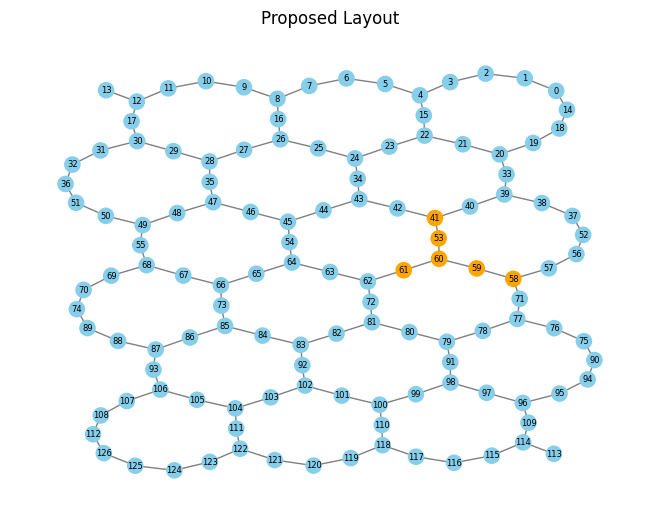

In [128]:
fied_mapping = initial_layout(tree, num_nodes=6, backend=backend, how='warm', topology='tree', root_on_backend=60) # here root_on_backend is the chosen root to build a bfs tree of n_nearest nodes from the root (in the backend)

prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=2)
opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=3)

show_layout_on_backend(opt_prop, backend, title="Proposed Layout", node_size=120)

Draw SABRE Layout on Backend

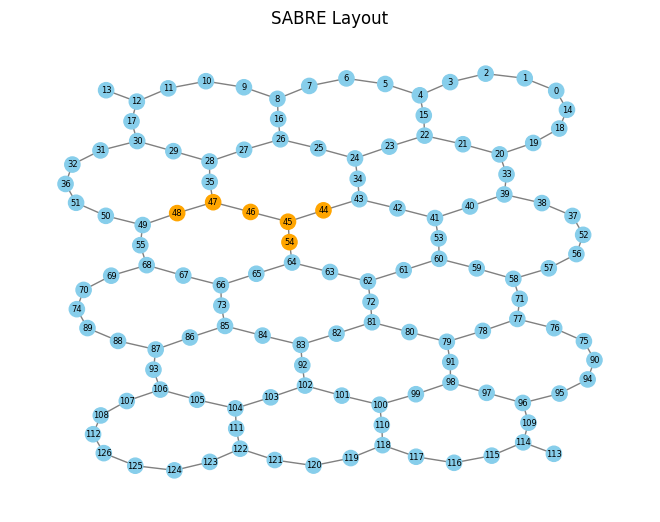

In [126]:
gen = gen_QAOA_circuit(graph, reps=2)

sabre_mapping = sabre_layout(gen, backend)
opt_sabre = final_optimized_circuit(gen, backend, sabre_mapping, opt_level=3)

show_layout_on_backend(opt_sabre, backend, title='SABRE Layout', node_size=120)

In [168]:
import warnings
warnings.filterwarnings("ignore")

## Results

In [276]:
from qiskit_ibm_runtime.fake_provider import FakeTorino

backend = FakeTorino()

In [163]:
backend.basis_gates

['cz', 'id', 'rz', 'sx', 'x']

In [277]:
# use this if running on simulator
from qiskit_aer import AerSimulator

sim = AerSimulator().from_backend(backend)

In [141]:
# use this if running on backend
sim = backend

### Regular Graphs

In [232]:
sim = AerSimulator()

In [252]:
num_nodes=6
param = 5

In [293]:
result = maxcut_dist(sim, backend, num_nodes=18, graph_type='reg', param=5, reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000, want_sabre=False, op_name='cz')
# mc_reg_6 = {'prop':result[0], 'sabre':result[1], 'def':result[2]}

Default=>  cz:  242 Depth:  373
Prop=>  cz:  257 Depth:  259


: 

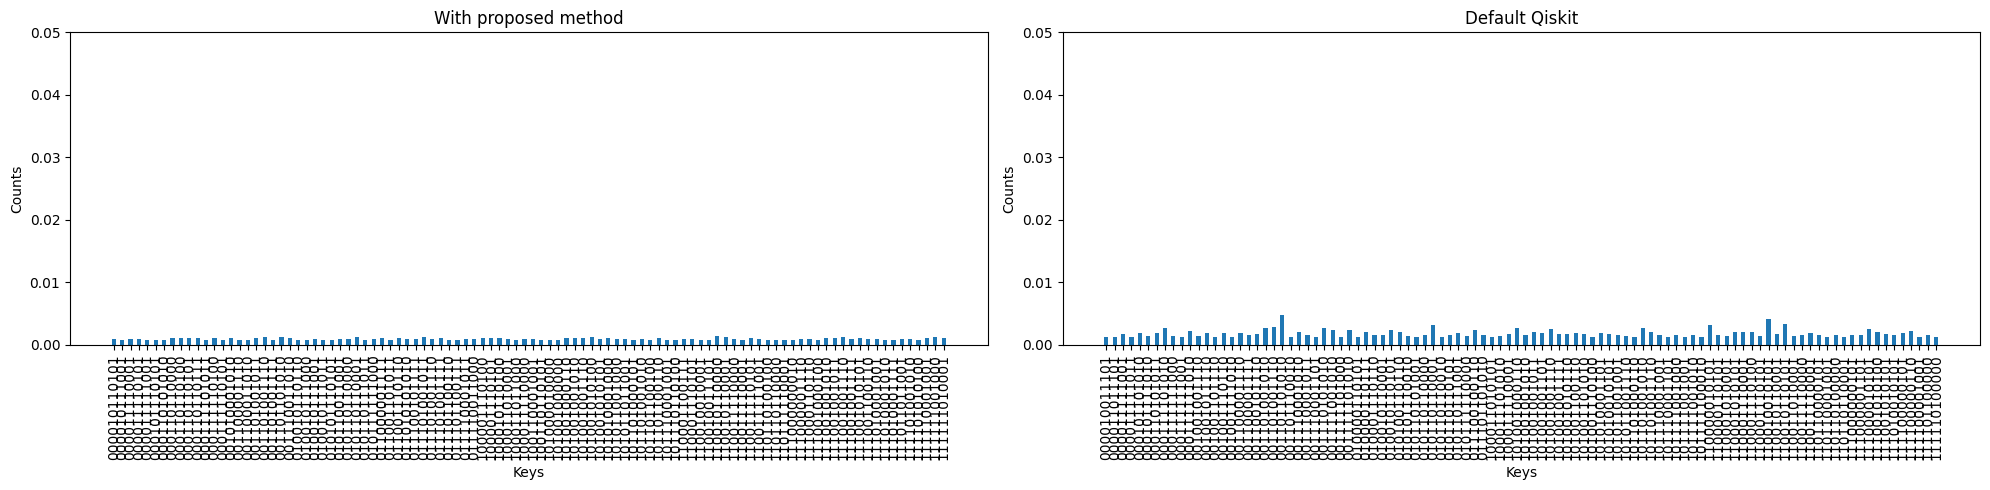

In [286]:
show_histograms(result, y_lim=0.05, keep_top=100, num_plots=2)

In [254]:
import numpy as np
from collections import defaultdict

# Store results for each bitstring across runs
probs = {'prop':defaultdict(list), 'sabre':defaultdict(list), 'def':defaultdict(list)}

# Run the function 100 times
for _ in tqdm(range(10)):
    result = maxcut_dist(sim, backend,num_nodes=num_nodes,graph_type='reg',param=param,reps=1,opt_level=3,estimator_shots=1000,sampler_shots=1000)

    for key, value in result.items():
        for bitstring, prob in value.items():
            probs[key][bitstring].append(prob)

100%|██████████| 10/10 [29:05<00:00, 174.53s/it]


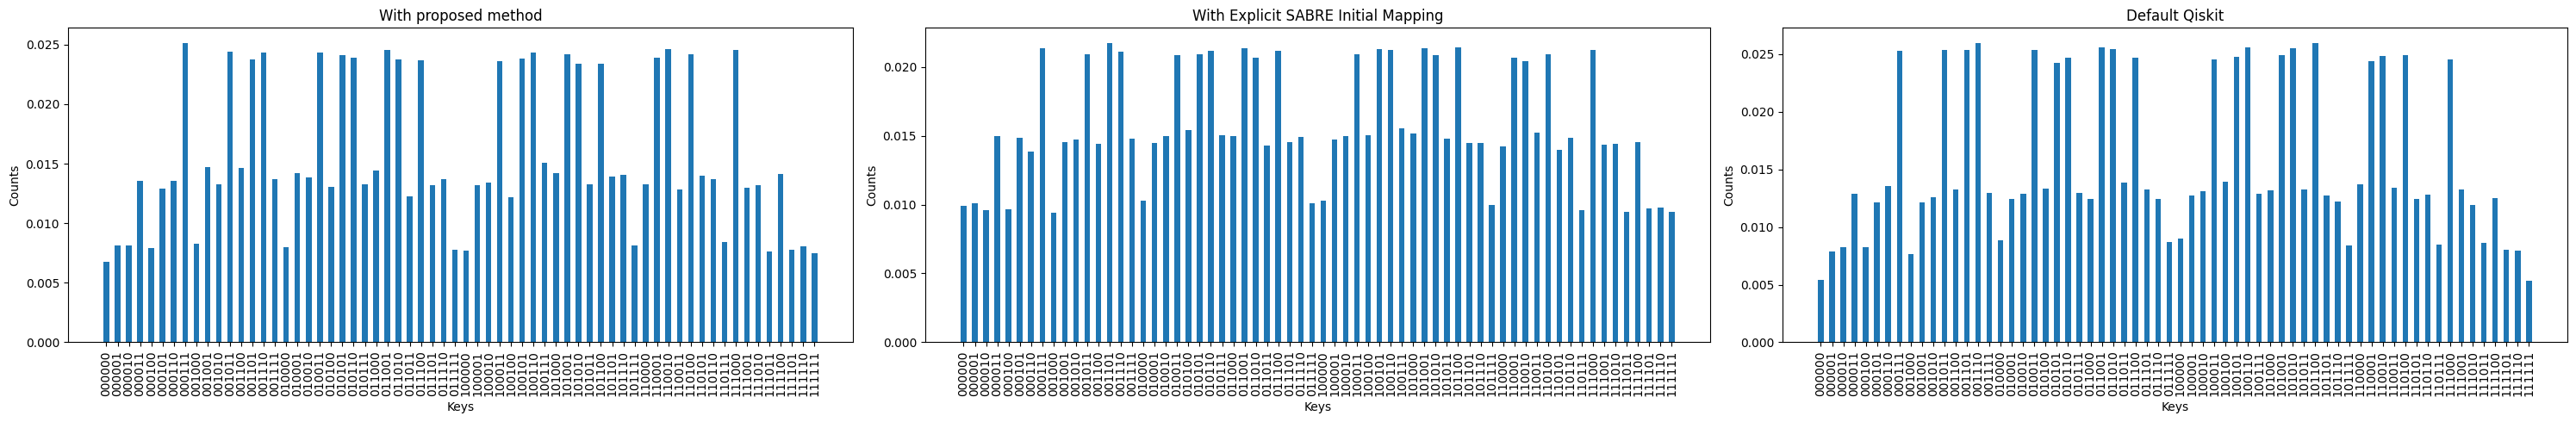

In [ ]:
# Compute mean and variance for each bitstring
stats_5reg_6 = {'mean':defaultdict(lambda: defaultdict(float)), 'var':defaultdict(lambda: defaultdict(float))}
for method, bit_list in probs.items():
    for bit, lst in bit_list.items():
        stats_5reg_6['mean'][method][bit] = np.mean(lst)
        stats_5reg_6['var'][method][bit] = np.var(lst)

show_histograms(stats_5reg_6['mean'])

with 10 nodes

In [273]:
import numpy as np
from collections import defaultdict

# Store results for each bitstring across runs
probs = {'prop':defaultdict(list), 'sabre':defaultdict(list), 'def':defaultdict(list)}

# Run the function 100 times
for _ in tqdm(range(100)):
    result = maxcut_dist(sim, backend, num_nodes=12,graph_type='reg',param=5,reps=1,opt_level=3,estimator_shots=1000,sampler_shots=1000, want_sabre=False)

    for key, value in result.items():
        if key!='sabre':
            for bitstring, prob in value.items():
                probs[key][bitstring].append(prob)


100%|██████████| 100/100 [6:39:26<00:00, 239.66s/it] 


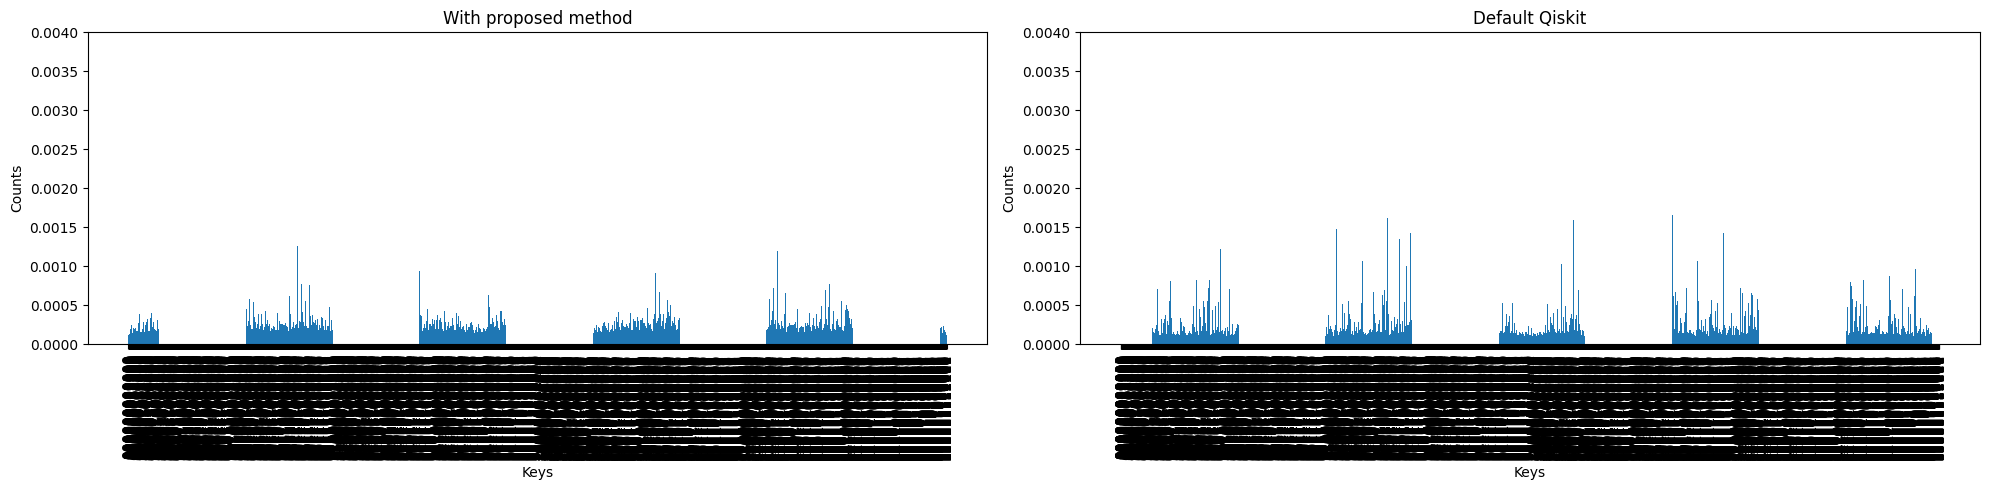

In [275]:

# Compute mean and variance for each bitstring
stats_5reg_14 = {'mean':defaultdict(lambda: defaultdict(float)), 'var':defaultdict(lambda: defaultdict(float))}
for method, bit_list in probs.items():
    if method!='sabre':
        for bit, lst in bit_list.items():
            stats_5reg_14['mean'][method][bit] = np.mean(lst)
            stats_5reg_14['var'][method][bit] = np.var(lst)

show_histograms(stats_5reg_14['mean'], num_plots=2, y_lim=0.004)

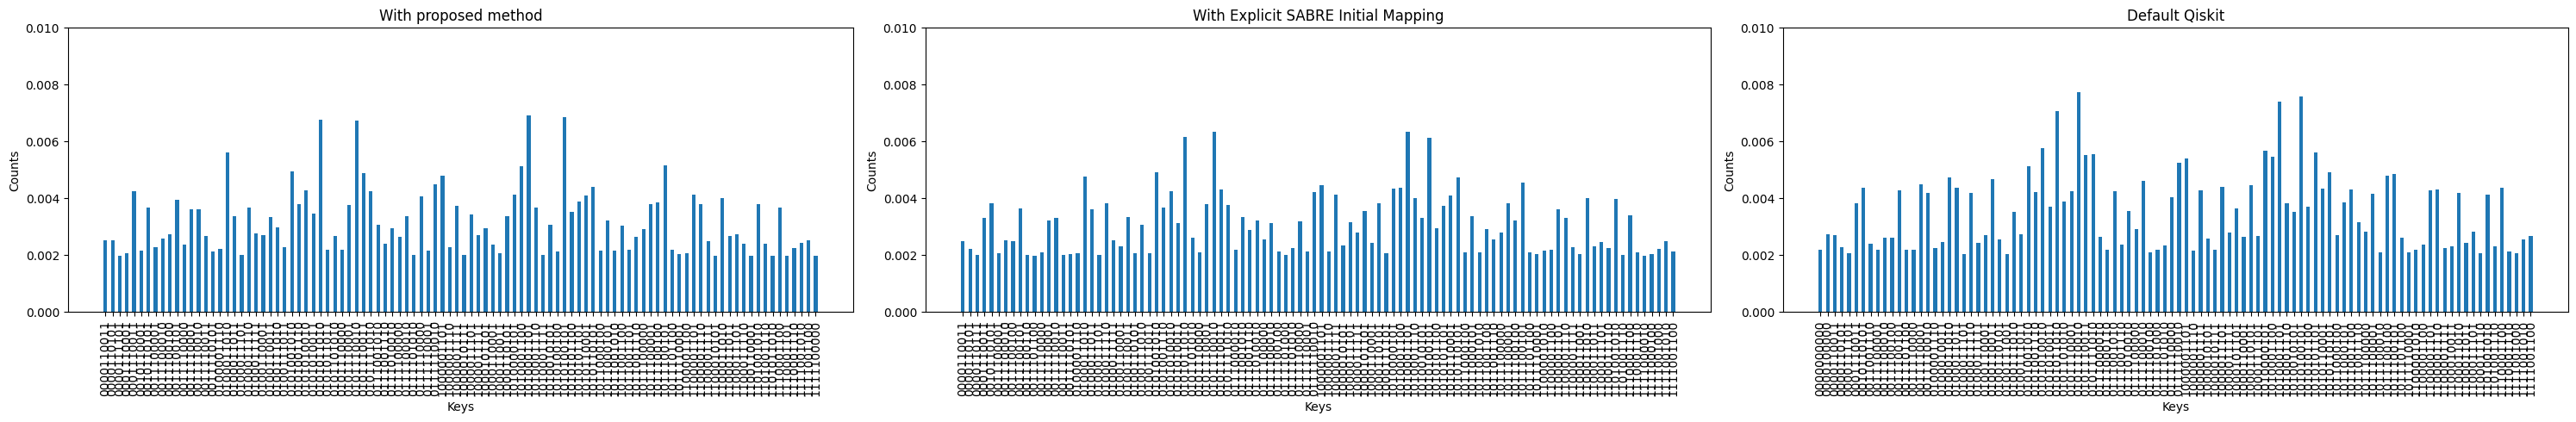

In [262]:
show_histograms(stats['mean'], keep_top=100, y_lim=0.01)

In [221]:
graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
cuts_reg = {'prop': evaluate_cut(graph, most_likely_cut(mc_proposed_reg)), 
        'sabre': evaluate_cut(graph, most_likely_cut(mc_sabre_reg)), 
        'def': evaluate_cut(graph, most_likely_cut(mc_default_reg)),
        'rand': evaluate_cut(graph, format(random.getrandbits(num_nodes), f'0{num_nodes}b'))}
        # 'rand': evaluate_cut(graph, '000111')}
print(cuts_reg)

cuts_ex = {'prop': expected_size(graph, mc_proposed_reg), 
        'sabre': expected_size(graph, mc_sabre_reg), 
        'def': expected_size(graph, mc_default_reg),
        'rand': random_size(graph, mc_proposed_reg)}
        # 'rand': evaluate_cut(graph, '000111')}
print(cuts_ex)

{'prop': 7.0, 'sabre': 7.0, 'def': 7.0, 'rand': 6.0}
{'prop': 5.695099999999999, 'sabre': 5.5364, 'def': 5.712700000000002, 'rand': 4.5}


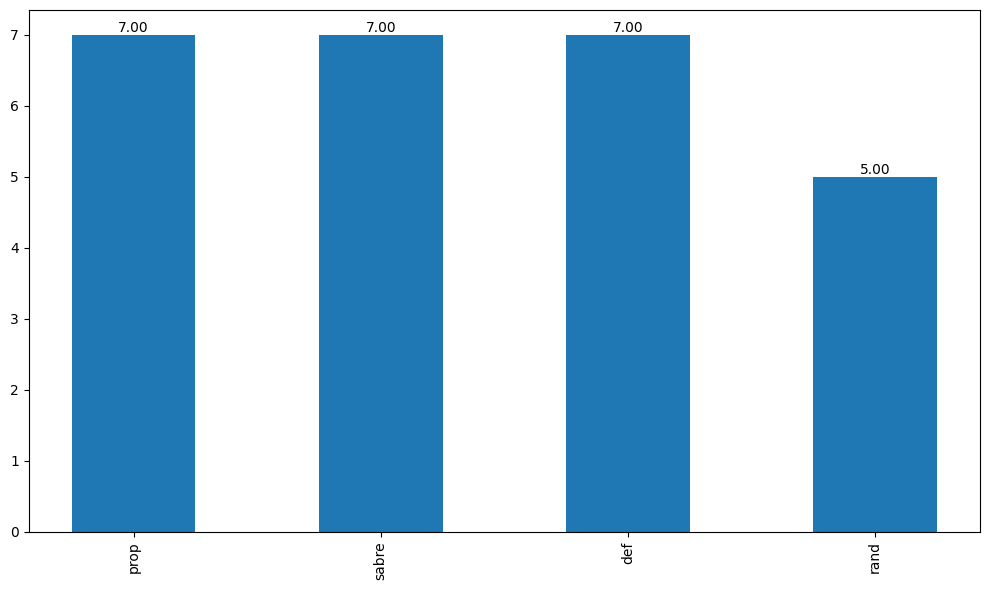

In [204]:
data = cuts_reg
keys = list(data.keys())
values = list(data.values())

width=0.5
plt.figure(figsize=(10, 6))
bars = plt.bar(keys, values, width=width)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}',
                ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=90)
# if title: plt.title(title)
# if xlabel: plt.xlabel(xlabel)
# if ylabel: plt.ylabel(ylabel)

plt.tight_layout()
plt.show()

### BA Graphs

In [206]:
num_nodes=6
param=3

In [207]:
mc_proposed_ba, mc_sabre_ba, mc_default_ba = maxcut_dist(backend, backend, num_nodes=num_nodes, graph_type='ba', param=param, reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000)

Default=>  cz:  30 Depth:  99
SABRE=>  cz:  30 Depth:  89
Prop=>  cz:  27 Depth:  87


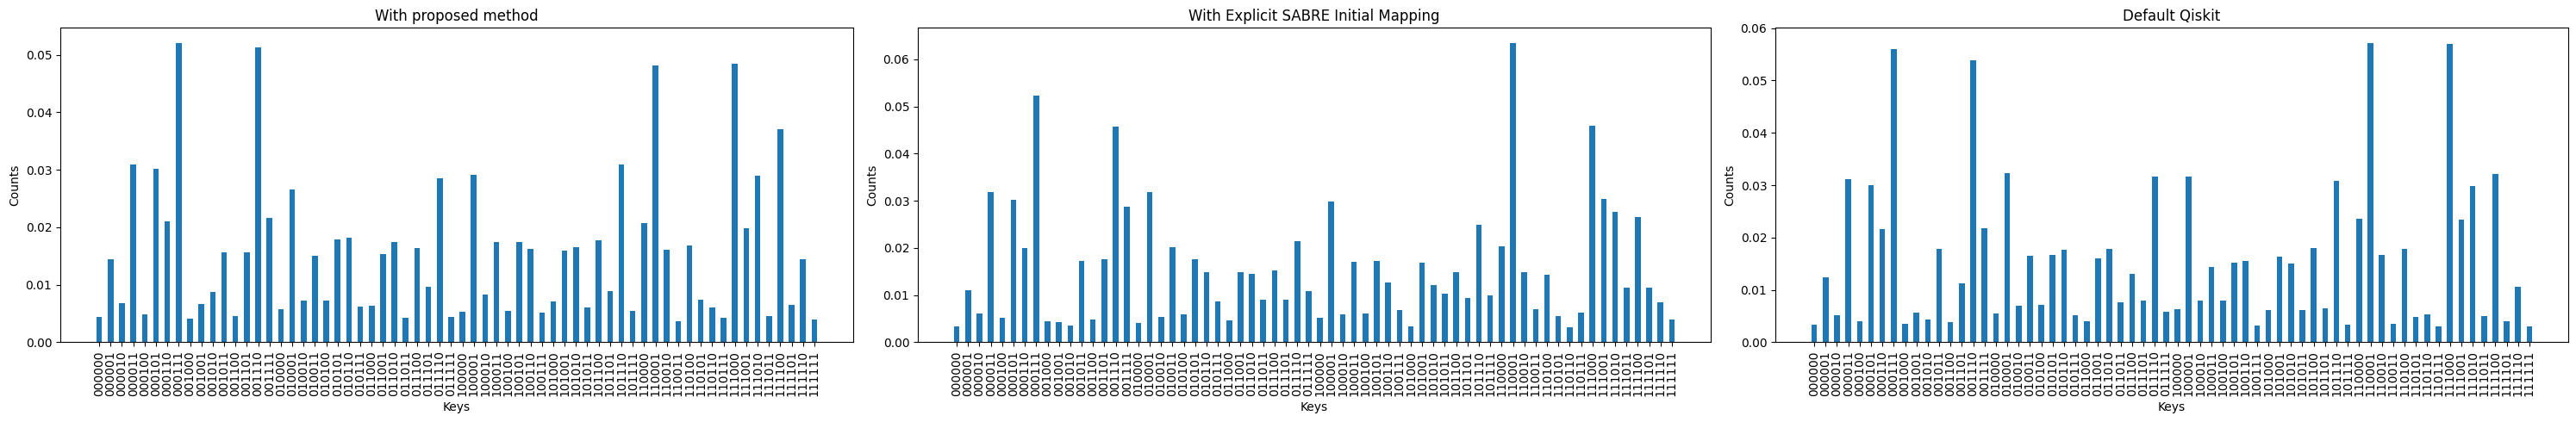

In [208]:
fig, axs = plt.subplots(1, 3, figsize=(30, 5))  # (rows, cols)

plot_histogram(mc_proposed_ba, ax=axs[0], keep_top=None)
plot_histogram(mc_sabre_ba, ax=axs[1], keep_top=None)
plot_histogram(mc_default_ba, ax=axs[2], keep_top=None)

axs[0].set_title("With proposed method")
axs[1].set_title("With Explicit SABRE Initial Mapping")
axs[2].set_title("Default Qiskit")

# # uncomment if want to see with consistent scale
# axs[0].set_ylim(0, 0.1)
# axs[1].set_ylim(0, 0.1)
# axs[2].set_ylim(0, 0.1)

plt.tight_layout()
plt.show()

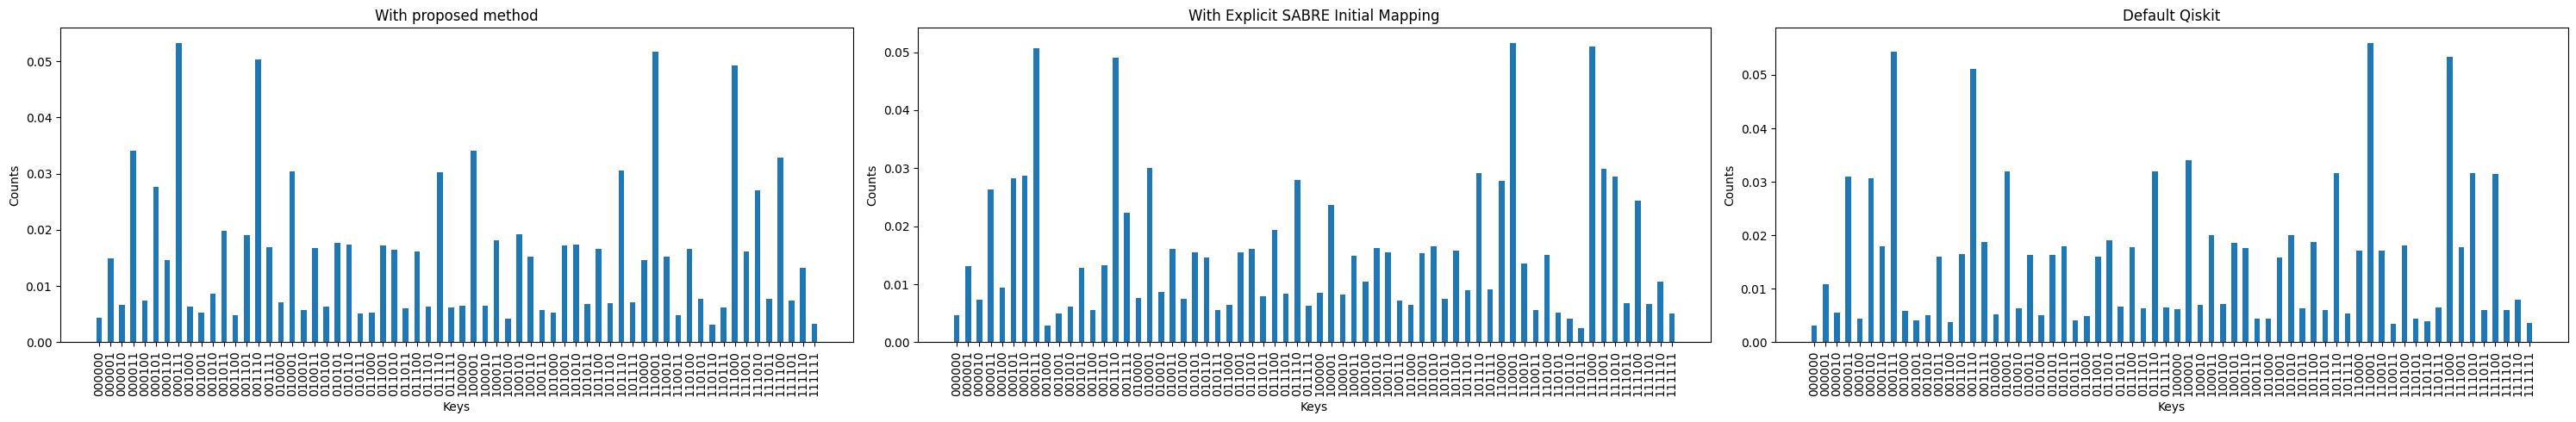

In [195]:
fig, axs = plt.subplots(1, 3, figsize=(30, 5))  # (rows, cols)

plot_histogram(mc_proposed_ba, ax=axs[0], keep_top=None)
plot_histogram(mc_sabre_ba, ax=axs[1], keep_top=None)
plot_histogram(mc_default_ba, ax=axs[2], keep_top=None)

axs[0].set_title("With proposed method")
axs[1].set_title("With Explicit SABRE Initial Mapping")
axs[2].set_title("Default Qiskit")

# # uncomment if want to see with consistent scale
# axs[0].set_ylim(0, 0.1)
# axs[1].set_ylim(0, 0.1)
# axs[2].set_ylim(0, 0.1)

plt.tight_layout()
plt.show()

In [196]:
graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)
cuts_ba = {'prop': evaluate_cut(graph, most_likely_cut(mc_proposed_ba)), 
        'sabre': evaluate_cut(graph, most_likely_cut(mc_sabre_ba)), 
        'def': evaluate_cut(graph, most_likely_cut(mc_default_ba)),
        'rand': evaluate_cut(graph, format(random.getrandbits(num_nodes), f'0{num_nodes}b'))}
        # 'rand': evaluate_cut(graph, '000111')}
cuts_ba

{'prop': 7.0, 'sabre': 7.0, 'def': 7.0, 'rand': 7.0}

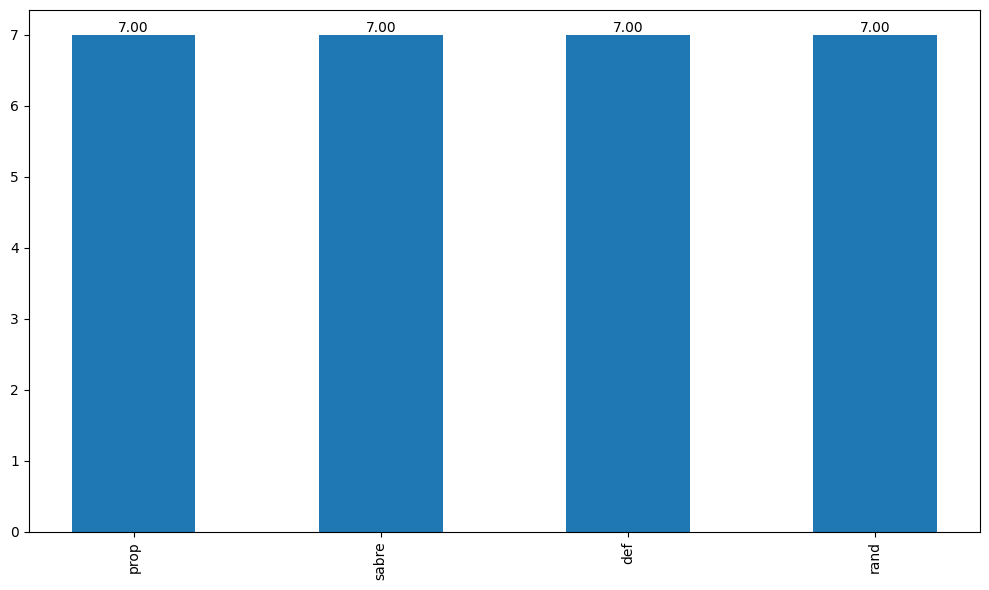

In [197]:
data = cuts_ba
keys = list(data.keys())
values = list(data.values())

width=0.5
plt.figure(figsize=(10, 6))
bars = plt.bar(keys, values, width=width)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}',
                ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=90)
# if title: plt.title(title)
# if xlabel: plt.xlabel(xlabel)
# if ylabel: plt.ylabel(ylabel)

plt.tight_layout()
plt.show()